<a href="https://colab.research.google.com/github/AnnaOlkh/BD-Lab1/blob/master/H%26M_Customer_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Сегментація клієнтів H&M методом K-means

**Мета роботи:** виділити групи клієнтів за купівельною поведінкою, оцінити якість і стійкість
кластерів та описати їхні відмінності.

Використано дані [H&M Personalized Fashion Recommendations](https://www.kaggle.com/competitions/h-and-m-personalized-fashion-recommendations/data):
історію покупок, довідник клієнтів і довідник товарів. Одиниця аналізу — клієнт.

1. Підготовка даних та формування ознак.
2. Розвідувальний аналіз і масштабування.
3. K-means та уточнення набору ознак.
4. Дослідження часового вікна і вибір фінальної моделі.
5. Оцінювання, профілі та візуалізація сегментів.
6. Висновки.


## 1. Підготовка даних
### 1.1. Завантаження та вибірка

Випадково відібрано 30 000 клієнтів із фіксованим seed. Для них збережено повну доступну
історію покупок: вибірка окремих транзакцій спотворила б частоту та давність покупок.
Великий CSV читається частинами. Ідентифікатори зберігаються як текст.


In [1]:
from pathlib import Path
import os, sys, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_samples, adjusted_rand_score
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits

SEED = 42
N_CUSTOMERS = 30_000
K_VALUES = range(2, 11)
SILHOUETTE_N = 2_000
SILHOUETTE_SEEDS = [42, 123, 2024]
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 16)

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/DataMining/raw_data')
    OUTPUT_DIR = DATA_DIR.parent / 'segmentation_final'
else:
    DATA_DIR = Path(os.environ.get('HM_DATA_DIR', 'raw_data'))
    OUTPUT_DIR = Path('segmentation_final')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def input_file(name):
    for candidate in [DATA_DIR / name, DATA_DIR / (name + '.zip')]:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f'Не знайдено {name} або {name}.zip у {DATA_DIR}')

versions = {'python': platform.python_version(), 'pandas': pd.__version__,
            'numpy': np.__version__, 'sklearn': sklearn.__version__}
print(versions)

from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score
import shutil
OUT = OUTPUT_DIR / 'tables'
OUT.mkdir(parents=True, exist_ok=True)
def save(table, name):
    display(table.round(4))
    table.to_csv(OUT / (name + '.csv'))
show_save = save


Mounted at /content/drive
{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'sklearn': '1.6.1'}


In [2]:
customers = pd.read_csv(input_file('customers.csv'), dtype={'customer_id': 'string'},
                        usecols=['customer_id', 'age'])
articles = pd.read_csv(input_file('articles.csv'), dtype={'article_id': 'string'},
                       usecols=['article_id', 'product_group_name'])
assert customers.customer_id.notna().all() and customers.customer_id.is_unique
assert articles.article_id.notna().all() and articles.article_id.is_unique
sampled_customers = customers.sample(n=min(N_CUSTOMERS, len(customers)), random_state=SEED).copy()
customer_ids = set(sampled_customers.customer_id)
parts = []
global_min, global_max = None, None
total_rows = 0
for chunk in pd.read_csv(input_file('transactions_train.csv'), chunksize=500_000,
                         dtype={'customer_id': 'string', 'article_id': 'string'},
                         usecols=['t_dat', 'customer_id', 'article_id', 'price', 'sales_channel_id']):
    # Дату зрізу визначаємо за всім джерелом, а не лише за вибіркою.
    chunk['t_dat'] = pd.to_datetime(chunk.t_dat, format='%Y-%m-%d', errors='coerce')
    if chunk.t_dat.isna().any():
        raise ValueError('У джерелі є некоректні дати; потрібна окрема перевірка.')
    lo, hi = chunk.t_dat.min(), chunk.t_dat.max()
    global_min = lo if global_min is None else min(global_min, lo)
    global_max = hi if global_max is None else max(global_max, hi)
    total_rows += len(chunk)
    parts.append(chunk.loc[chunk.customer_id.isin(customer_ids)].copy())
transactions = pd.concat(parts, ignore_index=True)
del parts, chunk
reference_date = global_max + pd.Timedelta(days=1)
print(f'Джерело: {total_rows:,} рядків; {global_min.date()} — {global_max.date()}')
print(f'Вибірка: {len(sampled_customers):,} клієнтів; {len(transactions):,} рядків')
print('Дата зрізу:', reference_date.date())


Джерело: 31,788,324 рядків; 2018-09-20 — 2020-09-22
Вибірка: 30,000 клієнтів; 685,262 рядків
Дата зрізу: 2020-09-23


### 1.2. Пропуски, повтори та узгодженість таблиць

Однакові рядки транзакцій не видаляли: без номера чека неможливо відрізнити помилку від купівлі
кількох однакових речей. Некоректні дати, ціни та ключі перевірено до агрегації.
Клієнтів без покупок обліковано окремо; їхню давність покупки не можна замінити нулем.


In [3]:
quality = pd.Series({
    'missing_customer': transactions.customer_id.isna().sum(),
    'missing_article': transactions.article_id.isna().sum(),
    'missing_price': transactions.price.isna().sum(),
    'nonfinite_price': (~np.isfinite(transactions.price)).sum(),
    'nonpositive_price': transactions.price.le(0).sum(),
    'unknown_channel': (~transactions.sales_channel_id.isin([1, 2])).sum(),
    'unknown_article': (~transactions.article_id.isin(articles.article_id)).sum(),
    'exact_repeat_rows': transactions.duplicated().sum(),
}, name='rows')
display(quality.to_frame())
assert quality.drop('exact_repeat_rows').eq(0).all(), 'Перевірте проблемні рядки перед моделюванням.'
active_ids = set(transactions.customer_id)
no_purchase = sampled_customers.loc[~sampled_customers.customer_id.isin(active_ids)].copy()
customers_sample = sampled_customers.loc[sampled_customers.customer_id.isin(active_ids)].copy()
print(f'З покупками: {len(customers_sample):,}; без покупок: {len(no_purchase):,}')
display(pd.DataFrame({'population': customers.age.describe(),
                      'random_sample': sampled_customers.age.describe(),
                      'buyers_sample': customers_sample.age.describe()}))


,rows
missing_customer,0
missing_article,0
missing_price,0
nonfinite_price,0
nonpositive_price,0
unknown_channel,0
unknown_article,0
exact_repeat_rows,64904


З покупками: 29,786; без покупок: 214


,population,random_sample,buyers_sample
count,1.356119e+06,29647.000000,29437.000000
mean,3.638696e+01,36.441427,36.455787
std,1.431363e+01,14.291127,14.284743
min,1.600000e+01,16.000000,16.000000
25%,2.400000e+01,24.000000,24.000000
50%,3.200000e+01,32.000000,32.000000
75%,4.900000e+01,49.000000,49.000000
max,9.900000e+01,92.000000,92.000000


Отримано **29 786 покупців і 685 262 рядки покупок**. Ще 214 відібраних клієнтів не мають
транзакцій у доступній історії. Розподіли віку у довіднику й вибірці близькі, проте це лише
часткова перевірка складу вибірки, а не доказ подібності всієї купівельної поведінки.

### 1.3. Формування ознак

| Ознака | Зміст |
|---|---|
| `recency` | Дні від останньої покупки до дати зрізу |
| `active_days` | Кількість календарних днів із покупками |
| `monetary` | Сума `price` у шкалі датасету |
| `avg_price` | Середня ціна на рядок покупки |
| `channel_2_share` | Частка рядків покупок у каналі 2 |
| `items_count`, `unique_products` | Обсяг покупок та різноманітність товарів |

`active_days` не є кількістю чеків, а `avg_price` — середнім чеком. Валюта `price` не встановлена.
Канали позначено їхніми кодами без припущення, який із них онлайн.
Вік і товарні категорії використано для опису, а не для розрахунку відстаней.
Пропущений вік залишено невідомим.


In [4]:
transactions['channel_2'] = transactions.sales_channel_id.eq(2).astype('int8')
customer_features = transactions.groupby('customer_id', sort=True).agg(
    last_purchase=('t_dat', 'max'), first_purchase=('t_dat', 'min'),
    active_days=('t_dat', 'nunique'), items_count=('article_id', 'size'),
    monetary=('price', 'sum'), avg_price=('price', 'mean'),
    unique_products=('article_id', 'nunique'), channel_2_share=('channel_2', 'mean'))
customer_features['recency'] = (reference_date - customer_features.last_purchase).dt.days
customer_features['observed_span_days'] = (customer_features.last_purchase - customer_features.first_purchase).dt.days
main_categories = ['Garment Upper body', 'Garment Lower body', 'Garment Full body',
                   'Underwear', 'Swimwear', 'Accessories', 'Shoes']
tx_categories = transactions.merge(articles, on='article_id', how='left', validate='many_to_one')
tx_categories['category'] = tx_categories.product_group_name.fillna('Unknown')
tx_categories['category'] = tx_categories.category.where(
    tx_categories.category.isin(main_categories + ['Unknown']), 'Other')
category_shares = pd.crosstab(tx_categories.customer_id, tx_categories.category, normalize='index').add_prefix('category_')
customer_features = customer_features.join(category_shares, validate='one_to_one').join(
    customers_sample.set_index('customer_id')[['age']], validate='one_to_one')
invalid_age = customer_features.age.notna() & ~customer_features.age.between(0, 120)
assert not invalid_age.any(), 'Вік поза допустимим діапазоном потребує перевірки.'
assert customer_features.index.is_unique
assert customer_features.items_count.sum() == len(transactions)
assert np.isclose(customer_features.monetary.sum(), transactions.price.sum())
assert np.allclose(customer_features[category_shares.columns].sum(axis=1), 1)
assert customer_features.recency.ge(1).all()
assert customer_features.channel_2_share.between(0, 1).all()
print('Пропуски віку (залишено для чесного профілювання):', customer_features.age.isna().sum())
display(customer_features.head())


Пропуски віку (залишено для чесного профілювання): 349


,last_purchase,first_purchase,active_days,items_count,monetary,avg_price,unique_products,channel_2_share,...,category_Garment Lower body,category_Garment Upper body,category_Other,category_Shoes,category_Swimwear,category_Underwear,category_Unknown,age
customer_id,,,,,,,,,,,,,,,,,
00036ffb474cd9818bd0d9045fd5863b0167aabae75e613722443c7b3264730d,2019-11-05,2018-11-23,9,25,0.906017,0.036241,22,1.000000,...,0.240000,0.240000,0.08,0.040000,0.080000,0.0,0.0,28.0
000383021a8cf9a542b9c855b42f99aa76374873661e831f56e225c58bd088ac,2018-10-30,2018-10-30,1,5,0.128068,0.025614,5,1.000000,...,0.200000,0.200000,0.00,0.000000,0.000000,0.0,0.0,30.0
0003c98542d16e740156638a7d133d93360d3ff3d0b7ec3ccb78932a915b1cfe,2018-11-23,2018-09-25,2,2,0.079627,0.039814,2,1.000000,...,0.000000,0.000000,0.00,0.000000,0.000000,0.0,0.0,22.0
0006d1fc72f81261e70e74249ab2c348e21a093ba40f2af6e90f4337a9736af2,2020-07-03,2018-10-24,13,53,1.363000,0.025717,44,0.924528,...,0.283019,0.377358,0.00,0.056604,0.000000,0.0,0.0,20.0
000f72a562e6a77624d7f6330b9bbaef1ecdfef26a9c14869b48607320c428ca,2020-09-13,2020-02-29,2,14,0.577729,0.041266,8,1.000000,...,0.071429,0.000000,0.00,0.000000,0.642857,0.0,0.0,36.0


## 2. Розвідувальний аналіз і масштабування
### 2.1. Розподіли та зв'язки між ознаками

Перевірено розподіли, крайні значення та кореляції Спірмена. Вона описує монотонні зв'язки
між рангами й підходить для порівняння асиметричних поведінкових показників.


,count,mean,std,min,1%,50%,95%,99%,max
recency,29786.0,236.803398,221.332710,1.000000,2.000000,154.000000,675.000000,725.000000,734.000000
active_days,29786.0,6.635634,9.725517,1.000000,1.000000,3.000000,25.000000,46.000000,189.000000
monetary,29786.0,0.639042,1.141628,0.001678,0.013542,0.242314,2.575839,5.487369,25.259119
avg_price,29786.0,0.028697,0.014412,0.001678,0.008458,0.026085,0.050831,0.084729,0.422034
channel_2_share,29786.0,0.658006,0.407034,0.000000,0.000000,0.909091,1.000000,1.000000,1.000000


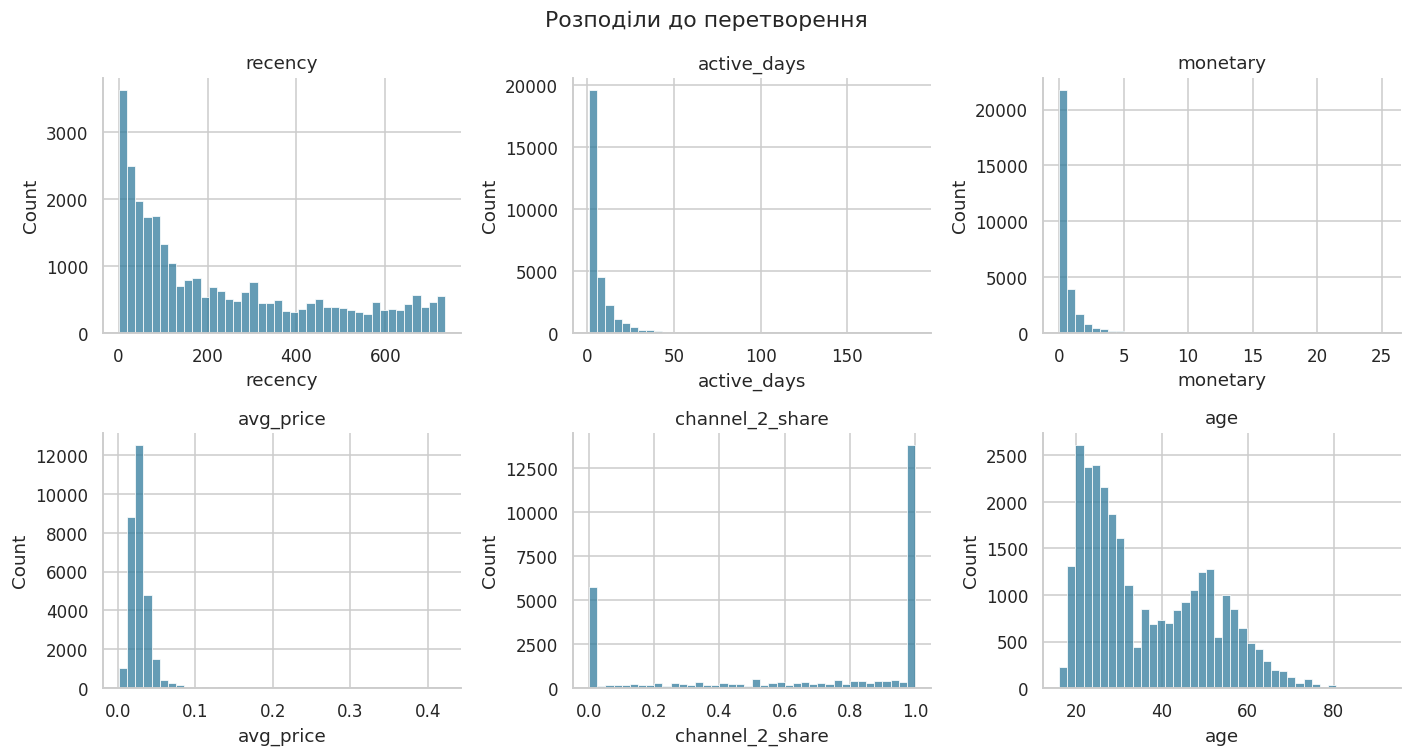

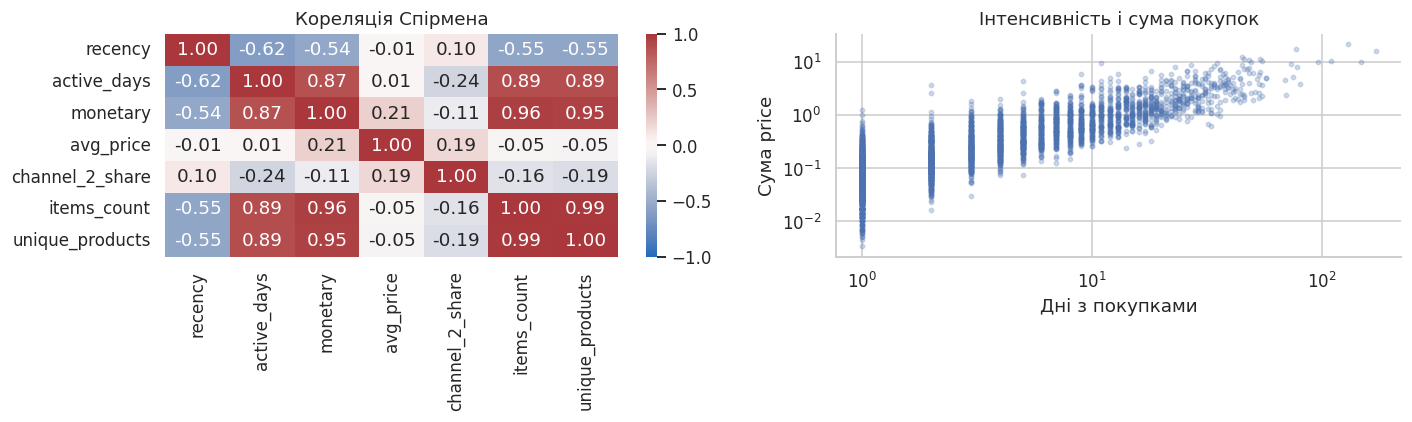

In [5]:
model_features = ['recency', 'active_days', 'monetary', 'avg_price', 'channel_2_share']
X_raw = customer_features[model_features].copy()
assert np.isfinite(X_raw.to_numpy()).all()
display(X_raw.describe(percentiles=[.01, .5, .95, .99]).T)
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, name in zip(axes.flat, model_features + ['age']):
    sns.histplot(customer_features[name].dropna(), bins=40, ax=ax, color='#327b9c')
    ax.set_title(name)
fig.suptitle('Розподіли до перетворення')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(customer_features[model_features + ['items_count', 'unique_products']].corr(method='spearman'),
            annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='vlag', ax=axes[0])
axes[0].set_title('Кореляція Спірмена')
view = customer_features.sample(n=min(4000, len(customer_features)), random_state=SEED)
axes[1].scatter(view.active_days, view.monetary, s=8, alpha=.25)
axes[1].set(xscale='log', yscale='log', xlabel='Дні з покупками', ylabel='Сума price',
            title='Інтенсивність і сума покупок')
plt.tight_layout(); plt.show()


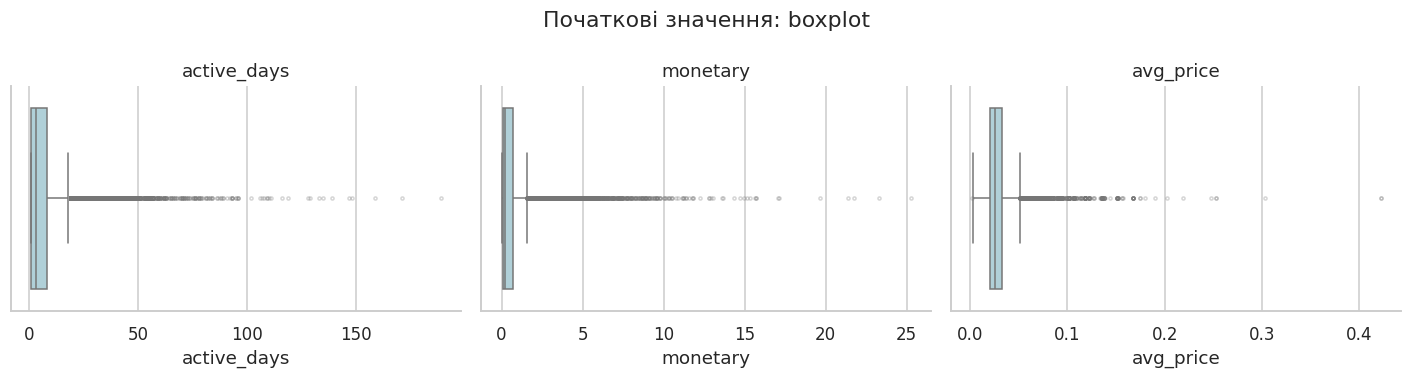

In [6]:
fig, axes = plt.subplots(1,3,figsize=(13,3.5))
for ax, name in zip(axes,['active_days','monetary','avg_price']):
    sns.boxplot(x=customer_features[name], ax=ax, color='#a9d4df', whis=1.5,
                flierprops={'markersize':2, 'alpha':.3})
    ax.set_title(name)
fig.suptitle('Початкові значення: boxplot')
plt.tight_layout(); plt.show()


Кількість рядків і кількість унікальних товарів сильно пов'язані (ρ ≈ 0.99), тому обидва
показники не включено до моделі. Частота та сума покупок також пов'язані (ρ ≈ 0.87);
їхній вплив додатково перевірено нижче. Точки за вусами boxplot не видаляли автоматично:
великий обсяг покупок може бути змістовною особливістю клієнта.

### 2.2. Перетворення та стандартизація

До додатних `active_days`, `monetary` та `avg_price` застосовано натуральний логарифм,
щоб зменшити вплив довгих хвостів. Потім усі ознаки стандартизовано через StandardScaler.
Recency залишено в днях, частку каналу — без логарифмування.
Для порівняння збережено варіант лише зі стандартизацією.


,baseline,log
max_absolute_z,,
recency,2.246414,2.246414
active_days,18.751438,3.587724
monetary,21.566124,3.573334
avg_price,27.293565,6.713145
channel_2_share,1.616617,1.616617


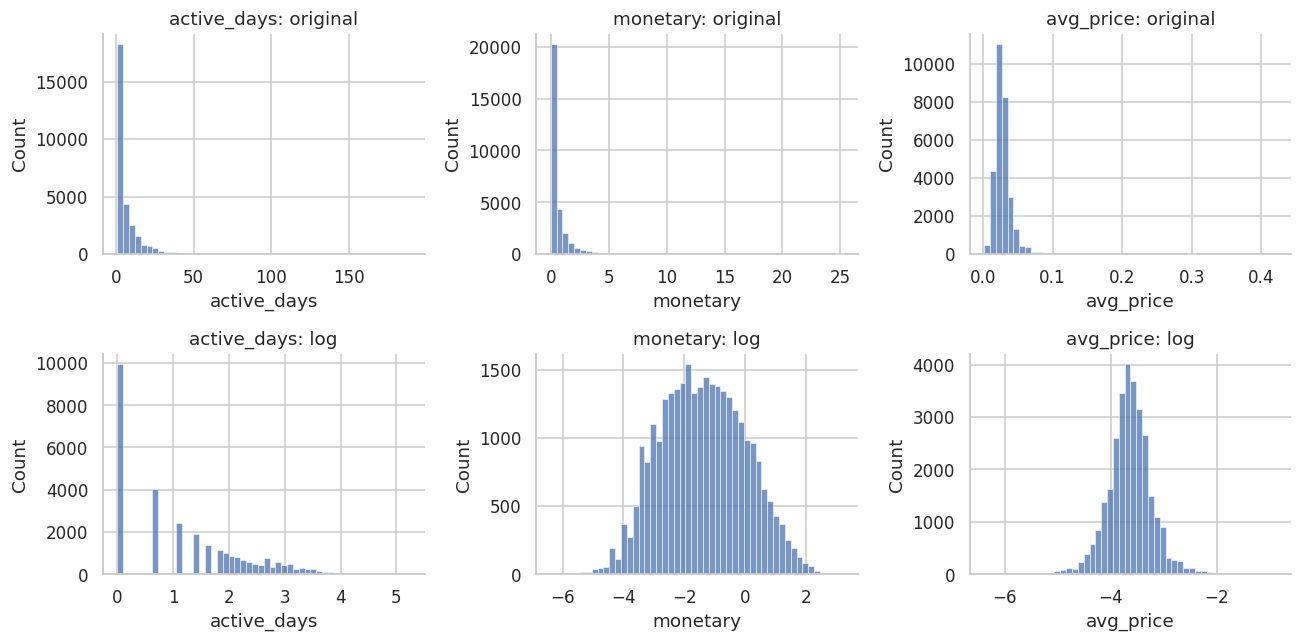

In [7]:
log_features = ['active_days', 'monetary', 'avg_price']
assert X_raw[log_features].gt(0).all().all()
X_log = X_raw.copy()
X_log[log_features] = np.log(X_log[log_features])
scalers = {'baseline': StandardScaler(), 'log': StandardScaler()}
spaces = {'baseline': scalers['baseline'].fit_transform(X_raw),
          'log': scalers['log'].fit_transform(X_log)}
for name, values in spaces.items():
    assert np.isfinite(values).all()
display(pd.DataFrame({name: np.abs(values).max(axis=0) for name, values in spaces.items()},
                     index=model_features).rename_axis('max_absolute_z'))
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for j, name in enumerate(log_features):
    sns.histplot(X_raw[name], bins=50, ax=axes[0,j])
    sns.histplot(X_log[name], bins=50, ax=axes[1,j])
    axes[0,j].set_title(name + ': original')
    axes[1,j].set_title(name + ': log')
plt.tight_layout(); plt.show()


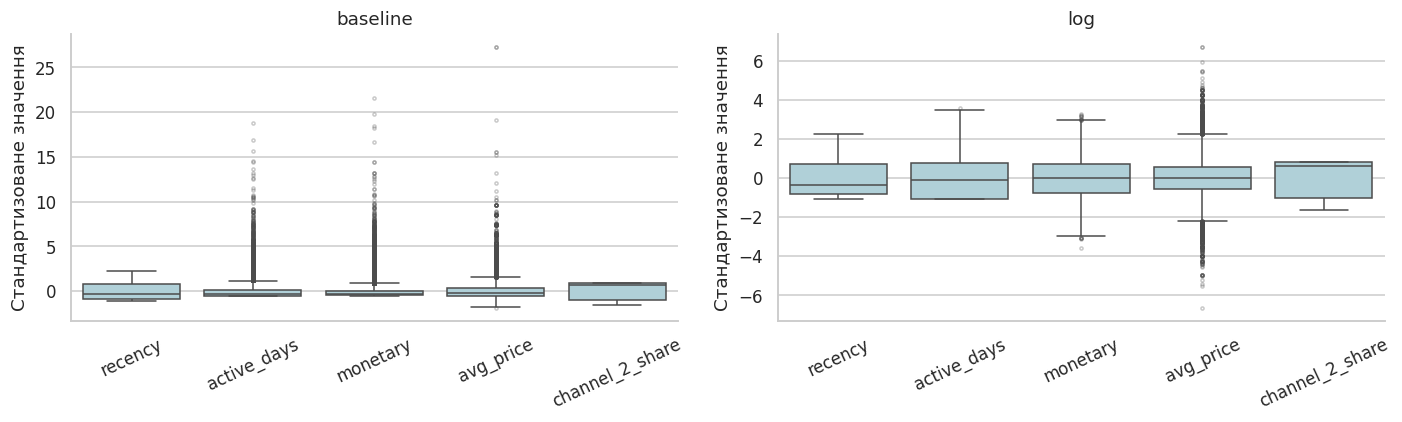

In [8]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
for ax,name in zip(axes,['baseline','log']):
    sns.boxplot(data=pd.DataFrame(spaces[name],columns=model_features), ax=ax, whis=1.5,
                color='#a9d4df', flierprops={'markersize':2,'alpha':.3})
    ax.set(title=name, ylabel='Стандартизоване значення')
    ax.tick_params(axis='x',rotation=25)
plt.tight_layout(); plt.show()
df = customer_features.copy()
features = model_features.copy()


In [9]:
L = df[features].copy()
L[['active_days','monetary','avg_price']] = np.log(L[['active_days','monetary','avg_price']])
Z = pd.DataFrame(StandardScaler().fit_transform(L), columns=features, index=df.index)
tails = Z.quantile([0,.001,.01,.5,.99,.999,1]).T
tails['abs_z_gt_3_share'] = Z.abs().gt(3).mean()
tails['abs_z_gt_4_share'] = Z.abs().gt(4).mean()
show_save(tails, 'tails')
extreme_idx = Z.avg_price.abs().nlargest(15).index
extreme = df.loc[extreme_idx, ['avg_price','items_count','active_days','monetary','recency']].copy()
extreme['avg_price_z'] = Z.loc[extreme_idx,'avg_price']
show_save(extreme.reset_index(drop=True), 'extreme_price_examples')


,0.0,0.001,0.01,0.5,0.99,0.999,1.0,abs_z_gt_3_share,abs_z_gt_4_share
recency,-1.0654,-1.0654,-1.0609,-0.3741,2.2058,2.2429,2.2464,0.0000,0.0000
active_days,-1.0809,-1.0809,-1.0809,-0.1024,2.3291,2.9388,3.5877,0.0007,0.0000
monetary,-3.5733,-2.6531,-2.0815,-0.0210,2.2079,2.7169,3.2986,0.0004,0.0000
avg_price,-6.6453,-3.9740,-2.7363,-0.0144,2.8328,4.2295,6.7131,0.0129,0.0024
channel_2_share,-1.6166,-1.6166,-1.6166,0.6169,0.8402,0.8402,0.8402,0.0000,0.0000


,avg_price,items_count,active_days,monetary,recency,avg_price_z
0,0.4220,1,1,0.4220,665,6.7131
1,0.4220,2,1,0.8441,656,6.7131
2,0.0017,1,1,0.0017,173,-6.6453
3,0.3034,1,1,0.3034,7,5.9155
4,0.0026,7,1,0.0185,399,-5.5441
5,0.2525,1,1,0.2525,105,5.4721
6,0.2525,1,1,0.2525,693,5.4721
7,0.0028,45,2,0.1252,403,-5.4238
8,0.2475,3,1,0.7424,693,5.4229
9,0.0030,1,1,0.0030,46,-5.2140


Після логарифмування максимальне |z| зменшилося з 18.75 до 3.59 для частоти та з 21.57 до 3.57
для суми покупок. Для середньої ціни залишилося |z| до 6.71, але лише 0.235% клієнтів мають
|z| > 4. Самого максимуму недостатньо для рішення про обрізання; нижче перевірено його вплив на кластери.

## 3. K-means і вибір ознак
### 3.1. Початкова модель

Початковий набір містить давність, частоту, суму, середню ціну та частку каналу 2.
Для кожного k використано 10 ініціалізацій. Silhouette оцінено на трьох однакових для всіх
кандидатів підвибірках по 2 000 клієнтів; наведений SD описує розкид між ними, не довірчий інтервал.

Inertia та Davies–Bouldin мають зменшуватися для компактніших розбиттів, silhouette і
Calinski–Harabasz — збільшуватися. Inertia сама по собі не визначає k: вона падає зі зростанням
кількості кластерів. Метрики розглядаємо разом із розмірами, профілями та стійкістю груп.
Порівняння значень між різними просторами ознак не є універсальним рейтингом моделей.


,inertia,silhouette_mean,silhouette_sd,davies_bouldin,calinski_harabasz,min_cluster_share,all_clusters_seen
k,,,,,,,
2,98571.7002,0.2998,0.0004,1.2977,15216.0586,0.4682,True
3,78469.2964,0.3104,0.0019,1.2917,13371.6927,0.1994,True
4,67969.3569,0.2733,0.0026,1.3196,11824.8522,0.1911,True
5,59091.8615,0.2551,0.0047,1.3350,11319.1723,0.1436,True
6,52436.0453,0.2608,0.0045,1.2069,10960.4278,0.1235,True
7,47952.7982,0.2481,0.0047,1.1591,10451.3148,0.1055,True
8,44146.1260,0.2520,0.0059,1.2128,10097.2195,0.0636,True
9,40909.3199,0.2536,0.0075,1.1694,9828.2793,0.0507,True
10,38359.7549,0.2497,0.0072,1.1515,9536.4736,0.0418,True


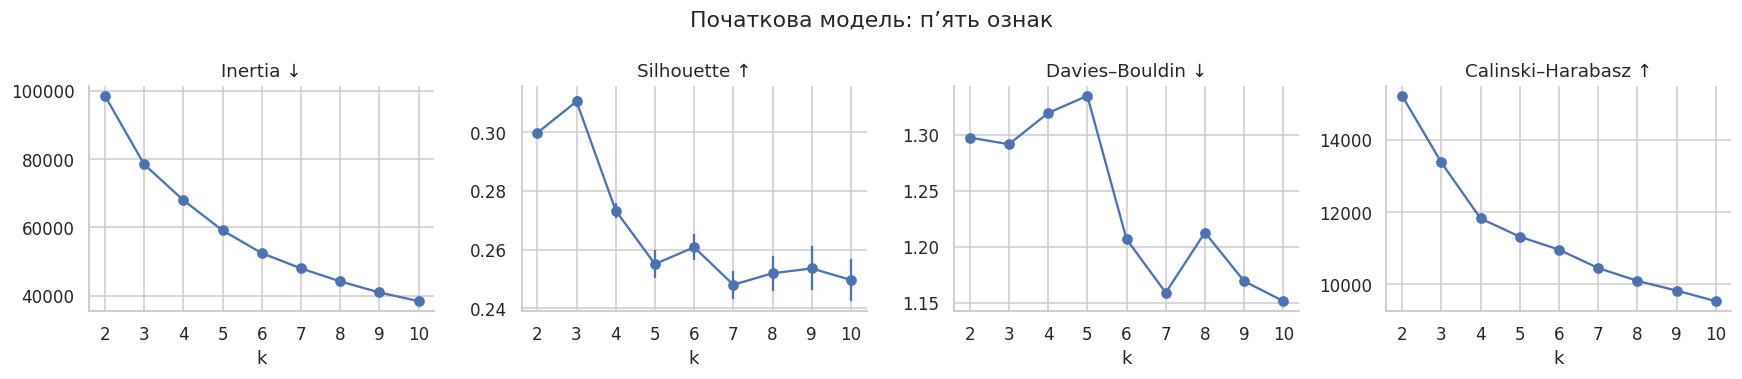

Початкове k: 3


,recency,active_days,monetary,avg_price,channel_2_share,customers
cluster,,,,,,
0,300.0,1.0,0.1049,0.0270,1.0000,11655
1,51.0,10.0,0.8521,0.0268,0.7333,12191
2,362.0,1.0,0.1067,0.0229,0.0000,5940


In [11]:
from sklearn.metrics import silhouette_score
def evaluate_grid(values, ks=range(2,9)):
    indices = [np.random.default_rng(seed).choice(len(values),size=min(2000,len(values)),replace=False)
               for seed in [42,123,2024]]
    fitted, rows = {}, []
    with threadpool_limits(limits=2):
        for k in ks:
            model = KMeans(n_clusters=k,n_init=10,random_state=42).fit(values)
            labels = model.labels_
            scores = [silhouette_score(values[i],labels[i])
                      if 1<len(np.unique(labels[i]))<len(i) else np.nan for i in indices]
            rows.append({'k':k,'inertia':model.inertia_, 'silhouette_mean':np.mean(scores),
                         'silhouette_sd':np.std(scores),
                         'davies_bouldin':davies_bouldin_score(values,labels),
                         'calinski_harabasz':calinski_harabasz_score(values,labels),
                         'min_cluster_share':np.bincount(labels).min()/len(values),
                         'all_clusters_seen':all(len(np.unique(labels[i]))==k for i in indices)})
            fitted[k] = model
    return pd.DataFrame(rows).set_index('k'), fitted

def choose_k(table):
    eligible = table.loc[table.min_cluster_share.ge(.01) & table.all_clusters_seen
                         & table.silhouette_mean.notna()]
    assert len(eligible), 'Немає моделі за правилом відбору.'
    return int(eligible.loc[eligible.silhouette_mean.ge(eligible.silhouette_mean.max()-.01)].index.min())

def plot_metrics(table, title):
    fig, axes = plt.subplots(1,4,figsize=(16,3.5))
    for ax,column,label in zip(axes,['inertia','silhouette_mean','davies_bouldin','calinski_harabasz'],
                              ['Inertia ↓','Silhouette ↑','Davies–Bouldin ↓','Calinski–Harabasz ↑']):
        if column=='silhouette_mean':
            ax.errorbar(table.index,table[column],yerr=table.silhouette_sd,marker='o')
        else:
            ax.plot(table.index,table[column],marker='o')
        ax.set(xlabel='k',title=label,xticks=table.index)
    fig.suptitle(title); plt.tight_layout(); plt.show()

initial_metrics, initial_models = evaluate_grid(Z.to_numpy(),range(2,11))
save(initial_metrics,'initial_k_metrics')
plot_metrics(initial_metrics,'Початкова модель: п’ять ознак')
initial_k = choose_k(initial_metrics)
df['cluster'] = initial_models[initial_k].labels_
print('Початкове k:',initial_k)
initial_profile = df.groupby('cluster')[model_features].median()
initial_profile['customers'] = df.groupby('cluster').size()
save(initial_profile,'initial_profiles')


Для відтворюваного вибору залишено кандидати з мінімальною часткою кластера 1% та представленням
усіх кластерів у підвибірках. Серед моделей у межах 0.01 від найкращого середнього silhouette
обрано найменше k. Це робоче правило компактної сегментації; інші метрики використано для перевірки,
а не для прихованої зміни критерію після перегляду результатів.

Початкова модель виділила три групи. Дві мали близькі медіани частоти та суми покупок,
але різко відрізнялися каналом. Тому далі перевірено, що саме визначає це розбиття.

### 3.2. Додаткове дослідження: вплив каналу та крайніх цін

Частка каналу розрахована для клієнта й може набувати проміжних значень. Однак значення 0 або 1
за короткої історії ще не свідчить про стійку перевагу певного каналу.


col_0,only_1,mixed,only_2,customers,only_1_share,mixed_share,only_2_share
items_count,,,,,,,
1,799,0,2123,2922,0.2734,0.0000,0.7266
2–5,2374,631,5118,8123,0.2923,0.0777,0.6301
6–20,1977,3291,4287,9555,0.2069,0.3444,0.4487
21+,541,6598,2047,9186,0.0589,0.7183,0.2228


Кількість різних значень частки: 2157
Частка клієнтів з обома каналами: 0.3531860605653663


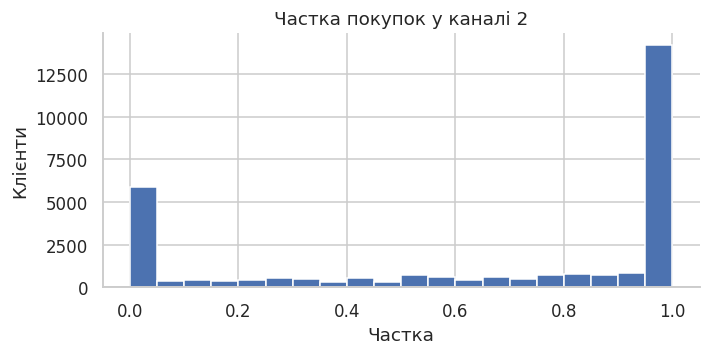

In [12]:
channel_type = pd.Series(np.select([df.channel_2_share.eq(0), df.channel_2_share.eq(1)],
                                    ['only_1','only_2'], default='mixed'), index=df.index)
history = pd.cut(df.items_count, bins=[0,1,5,20,np.inf], labels=['1','2–5','6–20','21+'])
channel_table = pd.crosstab(history, channel_type).reindex(columns=['only_1','mixed','only_2'], fill_value=0)
channel_table['customers'] = channel_table.sum(axis=1)
for c in ['only_1','mixed','only_2']:
    channel_table[c+'_share'] = channel_table[c] / channel_table.customers
show_save(channel_table, 'channel_by_history')
print('Кількість різних значень частки:', df.channel_2_share.nunique())
print('Частка клієнтів з обома каналами:', channel_type.eq('mixed').mean())
df.channel_2_share.hist(bins=20, figsize=(7,3))
plt.title('Частка покупок у каналі 2'); plt.xlabel('Частка'); plt.ylabel('Клієнти'); plt.show()


При k=3 по черзі прибрано канал, частоту та середню ціну. Окремо вдвічі зменшено вагу каналу
у квадраті відстані й обмежено avg_price квантилями 0.5% та 99.5% лише для перевірки чутливості.
ARI порівнює розбиття незалежно від номерів кластерів.
Додатковий silhouette у спільному просторі без каналу оцінює саме поведінкову компактність.


In [13]:
spaces = {'original': Z.to_numpy()}
weighted = Z.copy()
weighted['channel_2_share'] *= np.sqrt(.5)
spaces['half_channel_distance_weight'] = weighted.to_numpy()
spaces['without_channel'] = Z.drop(columns='channel_2_share').to_numpy()
spaces['without_active_days'] = Z.drop(columns='active_days').to_numpy()
spaces['without_avg_price'] = Z.drop(columns='avg_price').to_numpy()
capped = df[features].copy()
lower, upper = capped.avg_price.quantile([.005,.995])
cap_mask = ~capped.avg_price.between(lower, upper)
capped['avg_price'] = capped.avg_price.clip(lower, upper)
capped[['active_days','monetary','avg_price']] = np.log(capped[['active_days','monetary','avg_price']])
spaces['price_tail_sensitivity'] = StandardScaler().fit_transform(capped)
print('Цінові межі експерименту:', lower, upper, '; зачеплено клієнтів:', int(cap_mask.sum()))
idx = np.random.default_rng(42).choice(len(df), size=min(2000,len(df)), replace=False)
common = spaces['without_channel']
labels, fitted, comparison = {}, {}, []
def sil(values, groups):
    selected = groups[idx]
    return silhouette_score(values[idx], selected) if 1 < len(np.unique(selected)) < len(idx) else np.nan
with threadpool_limits(limits=2):
    for name, values in spaces.items():
        model = KMeans(n_clusters=3, n_init=10, random_state=42).fit(values)
        fitted[name], labels[name] = model, model.labels_
        residual = ((values - model.cluster_centers_[model.labels_])**2).sum(axis=1)
        top_n = max(1, int(np.ceil(.01*len(df))))
        comparison.append({'variant': name,
            'ARI_vs_original': adjusted_rand_score(labels['original'], model.labels_),
            'silhouette_own_space': sil(values, model.labels_),
            'silhouette_common_behavior_space': sil(common, model.labels_),
            'min_cluster_share': np.bincount(model.labels_).min()/len(df),
            'top_1pct_residual_share': np.sort(residual)[-top_n:].sum()/residual.sum()})
show_save(pd.DataFrame(comparison).set_index('variant'), 'comparison_k3')
if 'cluster' in df:
    print('ARI відтвореної базової моделі зі збереженою:', adjusted_rand_score(df.cluster, labels['original']))


# Частка міжкластерного розкиду, що припадає на кожну ознаку. Не причинна важливість.
base = fitted['original']
counts = np.bincount(base.labels_)
between = (counts[:,None] * (base.cluster_centers_ - Z.to_numpy().mean(axis=0))**2).sum(axis=0)
show_save(pd.DataFrame({'between_cluster_share': between/between.sum()}, index=features), 'separation_by_feature')


Цінові межі експерименту: 0.007456881940385697 0.1016779661016949 ; зачеплено клієнтів: 283


,ARI_vs_original,silhouette_own_space,silhouette_common_behavior_space,min_cluster_share,top_1pct_residual_share
variant,,,,,
original,1.0000,0.3124,0.2075,0.1994,0.0667
half_channel_distance_weight,0.5559,0.2808,0.3126,0.2710,0.0534
without_channel,0.5286,0.3281,0.3281,0.2793,0.0626
without_active_days,0.6835,0.2761,0.1535,0.2524,0.0759
without_avg_price,0.9684,0.3889,0.2084,0.1935,0.0362
price_tail_sensitivity,0.9989,0.3110,0.2075,0.1995,0.0525


ARI відтвореної базової моделі зі збереженою: 1.0


,between_cluster_share
recency,0.1469
active_days,0.2961
monetary,0.2543
avg_price,0.0117
channel_2_share,0.2910


Обрізання крайніх середніх цін майже не змінило розбиття (ARI ≈ 0.999), тому їх залишено.
Видалення каналу змінило модель значно сильніше (ARI ≈ 0.529). Канал пояснював близько 29.1%
міжкластерного розкиду. Для подальшої поведінкової сегментації його залишено в профілях.
Це вибір відповідно до мети аналізу, а не твердження, що канал непридатний для будь-якої кластеризації.

### 3.3. Сегментація без каналу


,inertia,silhouette_mean,silhouette_sd,davies_bouldin,calinski_harabasz,min_cluster_share,all_clusters_seen
k,,,,,,,
2,68896.4901,0.3675,0.0011,1.0499,21722.0611,0.4693,True
3,54493.4534,0.3245,0.0057,1.2850,17667.2126,0.2793,True
4,44716.2472,0.3004,0.0028,1.1201,16523.6545,0.1810,True
5,38727.7809,0.2595,0.0022,1.1483,15459.8358,0.1577,True
6,34176.0309,0.2618,0.0056,1.1408,14807.7732,0.0818,True
7,31039.6891,0.2615,0.0028,1.1314,14087.7480,0.0800,True
8,28610.6847,0.2518,0.0037,1.1531,13461.1316,0.0576,True


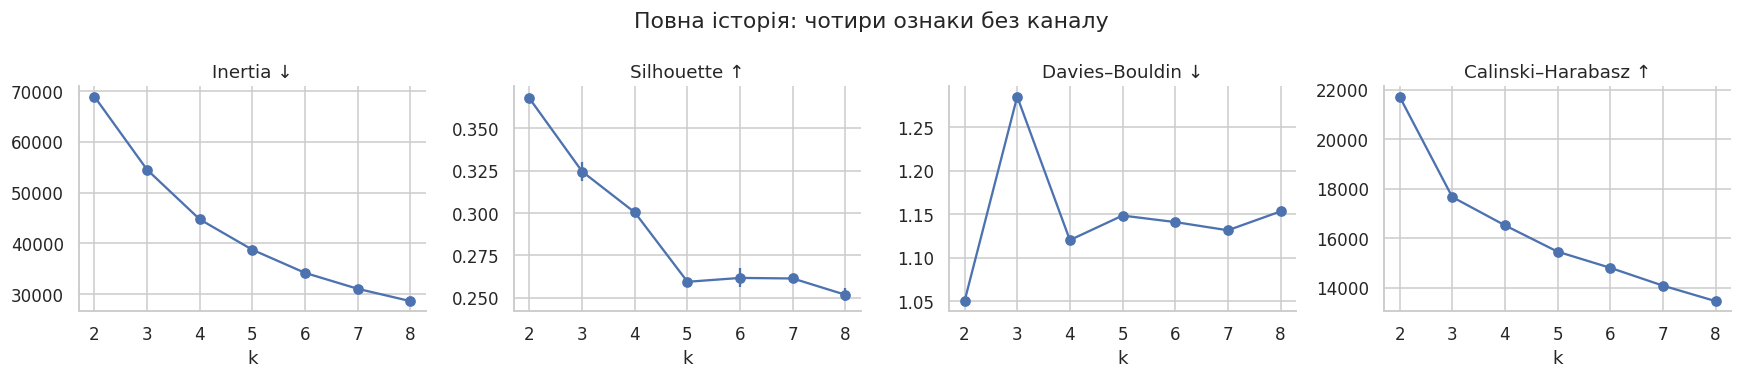

,recency,active_days,monetary,avg_price,channel_2_share,items_count,customers,customer_share,monetary_share
segment,,,,,,,,,
0,356.0,1.0,0.0932,0.0254,1.0000,4.0,15808,0.5307,0.1073
1,57.0,9.0,0.7353,0.0267,0.7429,28.0,13978,0.4693,0.8927


In [14]:
nochannel_metrics, nochannel_models = evaluate_grid(Z.drop(columns='channel_2_share').to_numpy())
save(nochannel_metrics,'without_channel_k_metrics')
plot_metrics(nochannel_metrics,'Повна історія: чотири ознаки без каналу')
nochannel_k = choose_k(nochannel_metrics)
nochannel_labels = nochannel_models[nochannel_k].labels_
temp = df.assign(segment=nochannel_labels)
g = temp.groupby('segment')
p = g[model_features+['items_count']].median()
p['customers'] = g.size()
p['customer_share'] = g.size()/len(df)
p['monetary_share'] = g.monetary.sum()/df.monetary.sum()
save(p,'without_channel_profiles')


Без каналу обрано два сегменти: активніша група становила 46.9% клієнтів і сформувала 89.3%
історичної суми покупок. Це опис концентрації витрат, а не незалежне підтвердження моделі,
оскільки monetary входить до її ознак.

## 4. Додаткове дослідження: вплив часового вікна
### 4.1. Великі історичні витрати та давність покупки

Накопичені витрати не обов'язково означають недавню активність. Перевірено гіпотезу:
серед клієнтів із великими історичними витратами є ті, хто давно не купував, а коротше
вікно агрегації може змінити їхню належність до сегментів.

Великі витрати визначено як верхній квартиль monetary. Межі давності 90, 180 і 365 днів
використано для опису; вони не є встановленими строками відтоку.


recency_band,1–90,91–180,181–365,366+
spend_group,,,,
other,5957,3707,4934,7741
top_quartile,5331,1128,726,262


recency_band,1–90,91–180,181–365,366+
spend_group,,,,
other,0.2667,0.1659,0.2209,0.3465
top_quartile,0.7159,0.1515,0.0975,0.0352


,days_since_purchase_gt,customers,share_of_high_spenders,share_of_all_customers,share_of_historical_monetary
0,90,2116,0.2841,0.0710,0.1573
1,180,988,0.1327,0.0332,0.0686
2,365,262,0.0352,0.0088,0.0151


col_0,False,True
cluster,,
0,11500,155
1,11377,814
2,5921,19


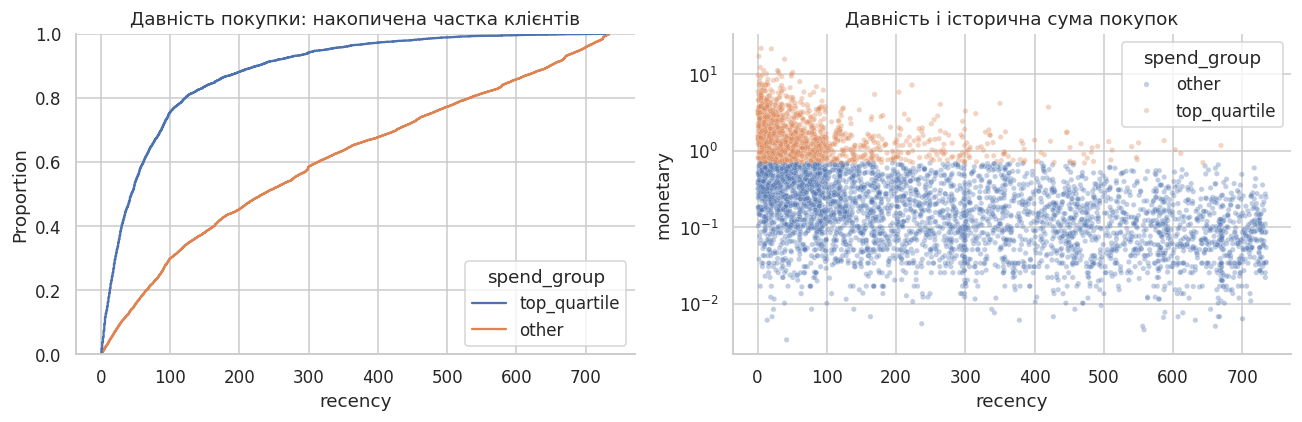

Межа верхнього квартиля суми price: 0.690851694915253


In [15]:
q75 = df.monetary.quantile(.75)
high = df.monetary.ge(q75)
work = df.assign(spend_group=np.where(high,'top_quartile','other'),
                 recency_band=pd.cut(df.recency, bins=[0,90,180,365,np.inf],
                                     labels=['1–90','91–180','181–365','366+']))
counts = pd.crosstab(work.spend_group,work.recency_band)
save(counts, 'spend_recency_counts')
save(counts.div(counts.sum(axis=1),axis=0), 'spend_recency_row_shares')
rows = []
for threshold in [90,180,365]:
    mask = high & df.recency.gt(threshold)
    rows.append({'days_since_purchase_gt':threshold, 'customers':int(mask.sum()),
                 'share_of_high_spenders':mask.sum()/high.sum(),
                 'share_of_all_customers':mask.mean(),
                 'share_of_historical_monetary':df.loc[mask,'monetary'].sum()/df.monetary.sum()})
save(pd.DataFrame(rows), 'high_spend_inactivity')
if 'cluster' in df:
    save(pd.crosstab(df.cluster,high & df.recency.gt(180)), 'original_clusters_high_spend_old')
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.ecdfplot(data=work, x='recency',hue='spend_group',ax=axes[0])
axes[0].set_title('Давність покупки: накопичена частка клієнтів')
view = work.sample(n=min(5000,len(work)),random_state=42)
sns.scatterplot(data=view,x='recency',y='monetary',hue='spend_group',s=12,alpha=.35,ax=axes[1])
axes[1].set_yscale('log'); axes[1].set_title('Давність і історична сума покупок')
plt.tight_layout(); plt.show()
print('Межа верхнього квартиля суми price:',q75)


Серед великих історичних покупців 988 клієнтів (13.3%) не купували понад 180 днів.
Вони становили 3.3% вибірки та сформували 6.9% історичної суми покупок.
Водночас 71.6% великих покупців купували протягом останніх 90 днів: виявлена проблема
стосується окремої групи, а не всіх клієнтів із великими витратами.

### 4.2. Формування річного вікна

Вікно охоплює 24.09.2019–22.09.2020; дата зрізу — 23.09.2020.
Рік охоплює повний сезонний цикл, хоча не усуває вплив сезонності чи зовнішніх подій.
Клієнтів без покупок за рік обліковано окремо, а не включено як штучний кластер K-means.


In [18]:
reference = reference_date
start = reference - pd.Timedelta(days=365)
recent_tx = transactions.loc[transactions.t_dat.ge(start) & transactions.t_dat.lt(reference)].copy()
assert len(recent_tx)
recent = recent_tx.groupby('customer_id').agg(last_purchase=('t_dat','max'),
    active_days=('t_dat','nunique'),monetary=('price','sum'),items_count=('price','size'),
    avg_price=('price','mean'),channel_2_share=('channel_2','mean'))
recent['recency'] = (reference-recent.last_purchase).dt.days
recent.index = recent.index.astype(str)
assert set(recent.index) == set(df.index[df.recency.le(365)]), 'Неузгоджені джерела або часові межі.'
assert recent.items_count.sum()==len(recent_tx)
assert np.isclose(recent.monetary.sum(),recent_tx.price.sum())
assert np.allclose(recent.recency,df.loc[recent.index,'recency'])
assert df.index.is_unique and recent.index.is_unique
assert recent.index.isin(df.index).all()

history_aligned = df.reindex(recent.index)
assert history_aligned[['active_days', 'monetary']].notna().all().all()

assert (
    recent['active_days'].to_numpy()
    <= history_aligned['active_days'].to_numpy()
).all()

assert (
    recent['monetary'].to_numpy()
    <= history_aligned['monetary'].to_numpy() + 1e-9
).all()
inactive = df.loc[~df.index.isin(recent.index)]
save(pd.DataFrame({'customers':[len(recent),len(inactive)],
                   'share_of_original_cohort':[len(recent)/len(df),len(inactive)/len(df)],
                   'historical_monetary_share':[df.loc[recent.index,'monetary'].sum()/df.monetary.sum(),
                                                inactive.monetary.sum()/df.monetary.sum()]},
                  index=['purchases_in_last_365_days','no_purchases_in_last_365_days']), 'cohort_accounting')
del recent_tx


,customers,share_of_original_cohort,historical_monetary_share
purchases_in_last_365_days,21783,0.7313,0.9293
no_purchases_in_last_365_days,8003,0.2687,0.0707


Покупки за останній рік мали 21 783 клієнти. Ще 8 003 покупці (26.9% початкової когорти)
не мали покупок у цьому вікні. Окремо від них залишаються 214 клієнтів, для яких немає
транзакцій у всій доступній історії.

### 4.3. Контрольоване порівняння

Для обох часових вікон використано **тих самих 21 783 клієнтів і три ознаки**:
recency, active_days, monetary. Середню ціну винесено у профілі, щоб зосередитися на
давності, частоті та сумі покупок. Вона не розрізняє середній чек і товарний склад.
Зміна набору ознак тут не змішується з ефектом вікна: в обох порівнюваних моделях набір однаковий.

Recency не змінюється; частота й сума рахуються за повною історією та за останній рік.
Кожний варіант окремо логарифмується й стандартизується.


,inertia,silhouette_mean,silhouette_sd,davies_bouldin,calinski_harabasz,min_cluster_share,all_clusters_seen
k,,,,,,,
2,31821.7881,0.4326,0.0034,0.8936,22948.3838,0.4838,True
3,22565.3571,0.4049,0.0050,0.9740,20647.3410,0.2424,True
4,17515.8900,0.3435,0.0062,0.9697,19825.3638,0.2170,True
5,13551.1840,0.3546,0.0024,0.8751,20811.0603,0.1363,True
6,11784.4580,0.3214,0.0013,0.9533,19797.3279,0.1254,True
7,10714.5844,0.3090,0.0040,1.0243,18506.7122,0.0810,True
8,9715.1692,0.3072,0.0039,0.9987,17813.7050,0.0813,True


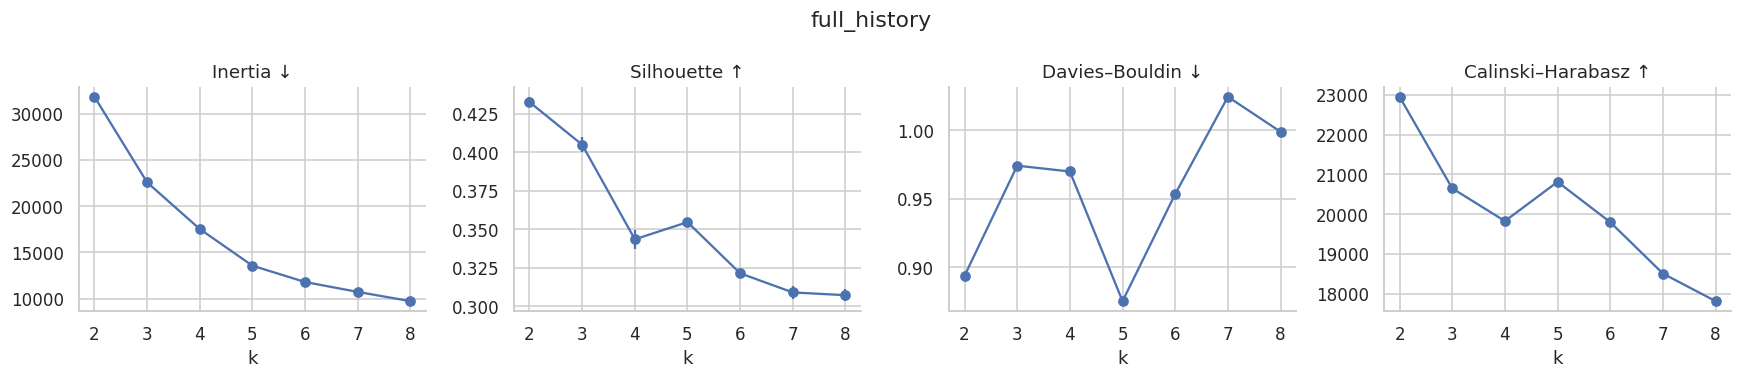

,inertia,silhouette_mean,silhouette_sd,davies_bouldin,calinski_harabasz,min_cluster_share,all_clusters_seen
k,,,,,,,
2,30763.8013,0.4407,0.0054,0.8586,24486.7129,0.4720,True
3,21120.0875,0.3888,0.0034,0.9539,22805.7558,0.2708,True
4,16300.9884,0.3501,0.0043,0.9421,21843.9593,0.2081,True
5,13713.7245,0.3441,0.0032,0.9521,20500.0588,0.1328,True
6,11956.6631,0.3087,0.0040,1.0181,19449.3117,0.1245,True
7,10852.5176,0.3013,0.0040,1.0301,18225.2042,0.1021,True
8,9842.5038,0.3016,0.0061,1.0204,17543.0662,0.0810,True


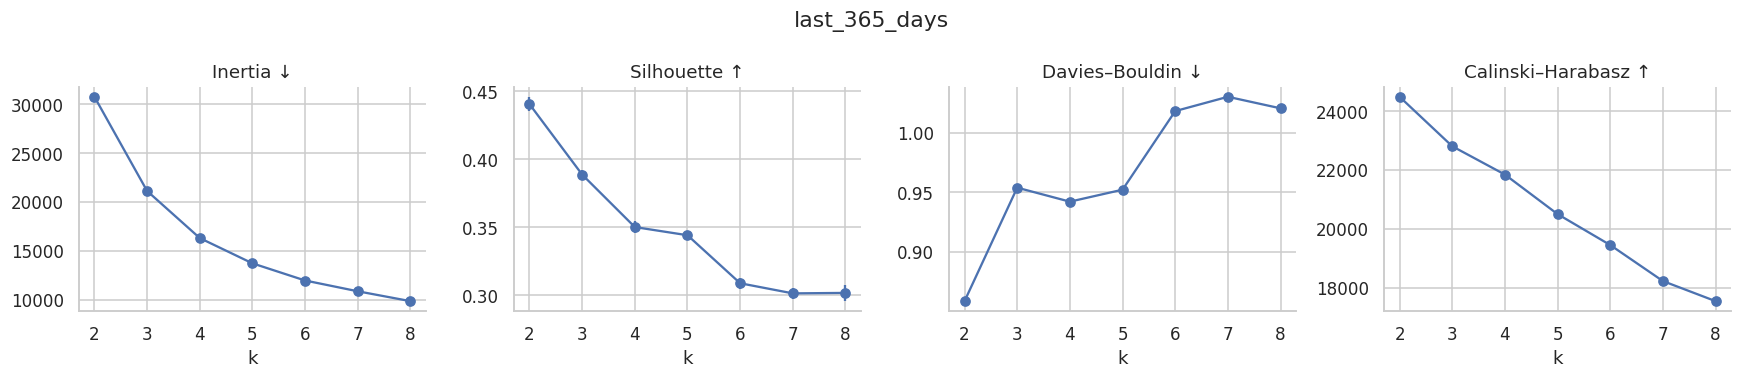

,k,inertia,silhouette_mean,silhouette_sd,davies_bouldin,calinski_harabasz,min_cluster_share,all_clusters_seen,window
0,2,31821.7881,0.4326,0.0034,0.8936,22948.3838,0.4838,True,full_history
1,3,22565.3571,0.4049,0.0050,0.9740,20647.3410,0.2424,True,full_history
2,4,17515.8900,0.3435,0.0062,0.9697,19825.3638,0.2170,True,full_history
3,5,13551.1840,0.3546,0.0024,0.8751,20811.0603,0.1363,True,full_history
4,6,11784.4580,0.3214,0.0013,0.9533,19797.3279,0.1254,True,full_history
5,7,10714.5844,0.3090,0.0040,1.0243,18506.7122,0.0810,True,full_history
6,8,9715.1692,0.3072,0.0039,0.9987,17813.7050,0.0813,True,full_history
7,2,30763.8013,0.4407,0.0054,0.8586,24486.7129,0.4720,True,last_365_days
8,3,21120.0875,0.3888,0.0034,0.9539,22805.7558,0.2708,True,last_365_days
9,4,16300.9884,0.3501,0.0043,0.9421,21843.9593,0.2081,True,last_365_days


Обрані k: {'full_history': 2, 'last_365_days': 2}


In [19]:
features = ['recency','active_days','monetary']
raw = {'full_history':df.loc[recent.index,features].copy(), 'last_365_days':recent[features].copy()}
logs, spaces, models, chosen, window_metrics = {}, {}, {}, {}, []
for name, table in raw.items():
    logs[name] = table.copy()
    logs[name][['active_days','monetary']] = np.log(table[['active_days','monetary']])
    spaces[name] = StandardScaler().fit_transform(logs[name])
    table_metrics, fitted = evaluate_grid(spaces[name])
    chosen[name] = choose_k(table_metrics)
    for k,model in fitted.items():
        models[name,k] = model
    window_metrics.append(table_metrics.reset_index().assign(window=name))
    save(table_metrics,name+'_metrics')
    plot_metrics(table_metrics,name)
save(pd.concat(window_metrics,ignore_index=True),'window_k_metrics')
print('Обрані k:',chosen)


In [20]:
ari = pd.DataFrame({'k':list(range(2,9)), 'ARI_between_windows':[
    adjusted_rand_score(models['full_history',k].labels_,models['last_365_days',k].labels_) for k in range(2,9)]})
save(ari,'same_k_window_ARI')
old = models['full_history',chosen['full_history']].labels_
new = models['last_365_days',chosen['last_365_days']].labels_
print('ARI обраних моделей:',adjusted_rand_score(old,new))
save(pd.crosstab(pd.Series(old,name='full_history_cluster'),pd.Series(new,name='annual_cluster'),
                 normalize='index'),'window_transitions')

profiles = []
for name, lab in [('full_history',old),('last_365_days',new)]:
    # Обидва розбиття описуємо в однакових поточних та історичних одиницях.
    p = recent[features+['items_count','channel_2_share']].add_suffix('_365').copy()
    p['historical_monetary'] = df.loc[recent.index,'monetary']
    p['historical_active_days'] = df.loc[recent.index,'active_days']
    p['segment'] = lab
    grouped = p.groupby('segment')
    profile = grouped.median().add_suffix('_median')
    profile['customers'] = grouped.size()
    profile['share_of_annual_cohort'] = grouped.size()/len(recent)
    profile['share_of_original_cohort'] = grouped.size()/len(df)
    profile['annual_monetary_share'] = grouped.monetary_365.sum()/recent.monetary.sum()
    profile['annual_monetary_q25'] = grouped.monetary_365.quantile(.25)
    profile['annual_monetary_q75'] = grouped.monetary_365.quantile(.75)
    profile['window'] = name
    profiles.append(profile.reset_index())
save(pd.concat(profiles,ignore_index=True),'window_profiles')

stability = []
with threadpool_limits(limits=2):
    for name in spaces:
        base_labels = models[name,chosen[name]].labels_
        for seed in [7,21,84]:
            train = np.random.default_rng(seed).choice(len(recent),size=int(.8*len(recent)),replace=False)
            scaler = StandardScaler().fit(logs[name].iloc[train])
            m = KMeans(n_clusters=chosen[name],n_init=10,random_state=seed).fit(scaler.transform(logs[name].iloc[train]))
            pred = m.predict(scaler.transform(logs[name]))
            stability.append({'window':name,'seed':seed,'ARI_resample':adjusted_rand_score(base_labels,pred)})
save(pd.DataFrame(stability),'window_stability')


,k,ARI_between_windows
0,2,0.5927
1,3,0.5946
2,4,0.5306
3,5,0.5012
4,6,0.4304
5,7,0.3819
6,8,0.4059


ARI обраних моделей: 0.5927450093761011


annual_cluster,0,1
full_history_cluster,,
0,0.9268,0.0732
1,0.1543,0.8457


,segment,recency_365_median,active_days_365_median,monetary_365_median,items_count_365_median,channel_2_share_365_median,historical_monetary_median,historical_active_days_median,customers,share_of_annual_cohort,share_of_original_cohort,annual_monetary_share,annual_monetary_q25,annual_monetary_q75,window
0,0,171.0,1.0,0.0847,3.0,1.0000,0.1270,2.0,10538,0.4838,0.3538,0.1417,0.0474,0.1525,full_history
1,1,44.0,5.0,0.4405,17.0,0.7576,0.8978,11.0,11245,0.5162,0.3775,0.8583,0.2406,0.8347,full_history
2,0,171.0,1.0,0.0847,3.0,1.0000,0.1449,2.0,11502,0.5280,0.3862,0.1501,0.0491,0.1490,last_365_days
3,1,38.0,6.0,0.4845,18.0,0.7647,0.9116,11.0,10281,0.4720,0.3452,0.8499,0.2866,0.8878,last_365_days


,window,seed,ARI_resample
0,full_history,7,0.9907
1,full_history,21,0.9993
2,full_history,84,0.9892
3,last_365_days,7,0.9974
4,last_365_days,21,0.9938
5,last_365_days,84,0.9991


В обох вікнах обрано k=2. Розбиття стійкі до навчання на різних 80% клієнтів (ARI ≈ 0.989–0.999),
проте ARI між часовими вікнами становить 0.593. Після зіставлення профілів 11.5% клієнтів
належать до іншої групи. Це різні класифікації на одну дату, а не фактичний перехід клієнтів у часі.

### 4.4. Де опинилися великі покупці з давньою останньою покупкою?


In [21]:
mapping = pd.DataFrame(index=df.index)
mapping['full_history_cluster_on_annual_cohort'] = pd.Series(old,index=recent.index)
mapping['annual_cluster'] = pd.Series(new,index=recent.index)
mapping['annual_group'] = mapping.annual_cluster.map(lambda x:f'cluster_{int(x)}' if pd.notna(x) else 'no_purchases_365')
target = high & df.recency.gt(180)
target_table = mapping.loc[target].groupby('annual_group').size().to_frame('customers')
target_table['share_of_target_group'] = target_table.customers/max(1,int(target.sum()))
save(target_table,'high_spend_old_annual_groups')
target_active = target.reindex(recent.index)
save(pd.crosstab(pd.Series(old,index=recent.index,name='full_history_cluster').loc[target_active],
                 pd.Series(new,index=recent.index,name='annual_cluster').loc[target_active]),
     'high_spend_old_window_transitions')


,customers,share_of_target_group
annual_group,,
cluster_0,537,0.5435
cluster_1,189,0.1913
no_purchases_365,262,0.2652


annual_cluster,0,1
full_history_cluster,,
0,189,12
1,348,177


Із 988 великих історичних покупців із давністю понад 180 днів 262 взагалі не купували за рік.
Серед решти 726 клієнтів модель за повною історією віднесла 525 до активнішого профілю;
348 із них (66.3%) річна модель віднесла до менш активного.

Отже, довга історія може приховувати давню останню покупку за високими накопиченими показниками.
Для опису недавньої поведінки далі використано річну модель. Рік не вважається універсально
оптимальним горизонтом, а історичні витрати збережено як додатковий контекст.

## 5. Фінальна модель: оцінювання та візуалізація
### 5.1. Якість кластерів

Фінальна модель використовує три ознаки за річним вікном. Silhouette обчислюється у повному
тривимірному просторі; PCA не бере участі у навчанні. Для оцінки неоднозначних присвоєнь
додатково показано silhouette окремих клієнтів на фіксованій підвибірці.


,customers_in_sample,silhouette_mean,negative_share
cluster,,,
0,1073,0.3827,0.0447
1,927,0.4971,0.0000


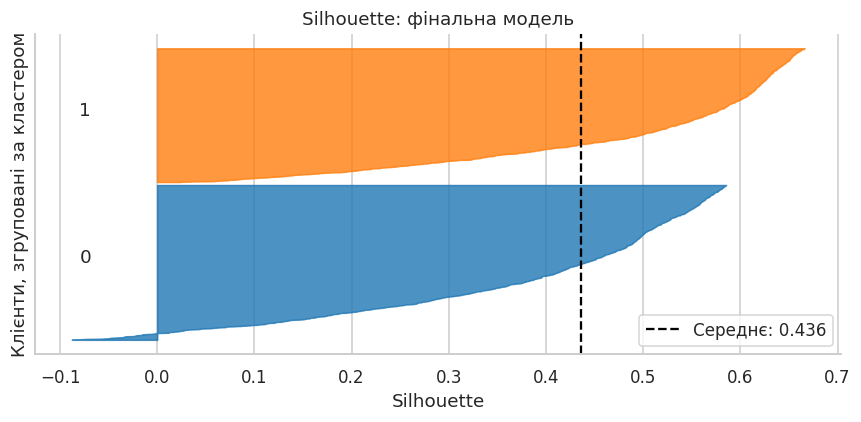

In [22]:
final_k = chosen['last_365_days']
final_model = models['last_365_days',final_k]
final_values = spaces['last_365_days']
final_labels = final_model.labels_
idx = np.random.default_rng(42).choice(len(recent),size=min(2000,len(recent)),replace=False)
with threadpool_limits(limits=2):
    s = silhouette_samples(final_values[idx],final_labels[idx])
detail = pd.DataFrame({'cluster':final_labels[idx],'silhouette':s})
save(detail.groupby('cluster').agg(customers_in_sample=('silhouette','size'),
     silhouette_mean=('silhouette','mean'),negative_share=('silhouette',lambda x:x.lt(0).mean())),
     'final_silhouette_by_cluster')
fig, ax = plt.subplots(figsize=(8,4))
bottom = 0
colors = sns.color_palette('tab10',final_k)
for cluster in range(final_k):
    values = np.sort(s[final_labels[idx]==cluster])
    ax.fill_betweenx(np.arange(bottom,bottom+len(values)),0,values,color=colors[cluster],alpha=.8)
    ax.text(-.08,bottom+len(values)/2,str(cluster))
    bottom += len(values)+20
ax.axvline(s.mean(),color='black',linestyle='--',label=f'Середнє: {s.mean():.3f}')
ax.set(xlabel='Silhouette',ylabel='Клієнти, згруповані за кластером',title='Silhouette: фінальна модель')
ax.set_yticks([]); ax.legend(); plt.tight_layout(); plt.show()


Середній silhouette на трьох підвибірках становив близько 0.441.
Це внутрішня характеристика розділення, а не точність прогнозу або доказ ефективності кампаній.

### 5.2. Профілі у початкових одиницях


,recency_median,active_days_median,monetary_median,items_count_median,avg_price_median,channel_2_share_median,age_median,customers,share_of_annual_cohort,share_of_original_cohort,annual_monetary_share,age_known_share
cluster,,,,,,,,,,,,
0,171.0,1.0,0.0847,3.0,0.0254,1.0000,31.0,11502,0.528,0.3862,0.1501,0.9892
1,38.0,6.0,0.4845,18.0,0.0270,0.7647,30.0,10281,0.472,0.3452,0.8499,0.9965


,recency,active_days,monetary
cluster,,,
0,177.9810,1.4496,0.1171
1,51.8879,7.6168,0.7420


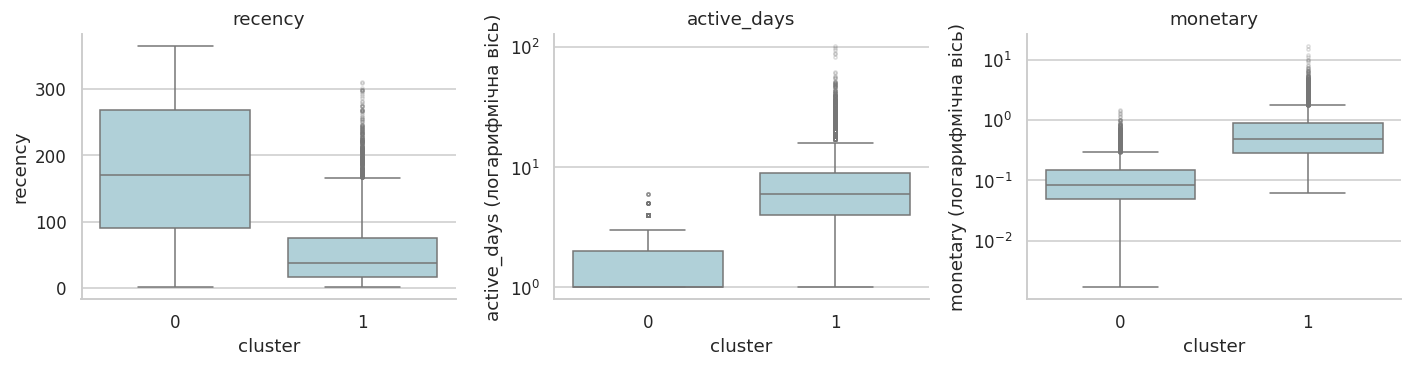

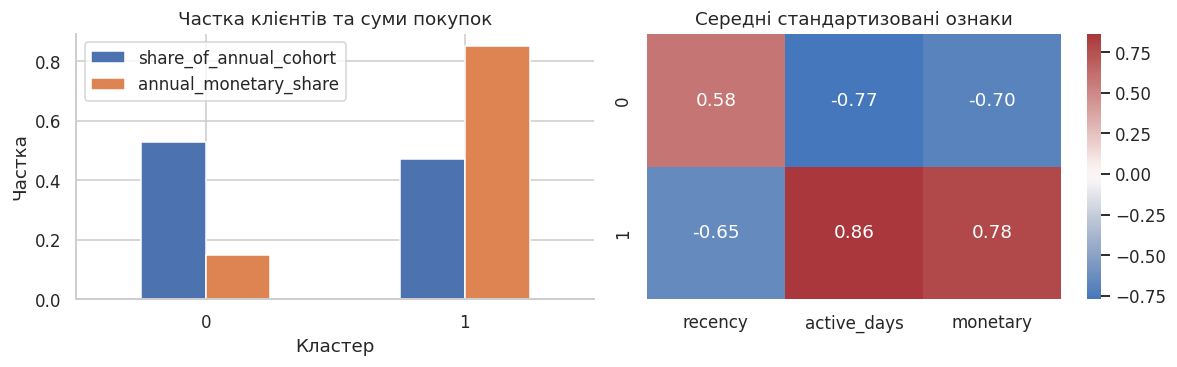

In [23]:
final_customers = recent.copy()
final_customers['cluster'] = final_labels
final_customers['age'] = df.loc[recent.index,'age']
g = final_customers.groupby('cluster')
final_profile = g[features+['items_count','avg_price','channel_2_share','age']].median().add_suffix('_median')
final_profile['customers'] = g.size()
final_profile['share_of_annual_cohort'] = g.size()/len(recent)
final_profile['share_of_original_cohort'] = g.size()/len(df)
final_profile['annual_monetary_share'] = g.monetary.sum()/recent.monetary.sum()
final_profile['age_known_share'] = g.age.count()/g.size()
save(final_profile,'final_cluster_profiles')
save(g[features].mean(),'final_cluster_means')
fig, axes = plt.subplots(1,3,figsize=(13,3.5))
for ax,name in zip(axes,features):
    sns.boxplot(data=final_customers,x='cluster',y=name,ax=ax,color='#a9d4df',
                flierprops={'markersize':2,'alpha':.25})
    if name!='recency':
        ax.set_yscale('log')
        ax.set_ylabel(name+' (логарифмічна вісь)')
    ax.set_title(name)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1,2,figsize=(11,3.5))
final_profile[['share_of_annual_cohort','annual_monetary_share']].plot.bar(ax=axes[0],rot=0)
axes[0].set(title='Частка клієнтів та суми покупок',ylabel='Частка',xlabel='Кластер')
centers = pd.DataFrame(final_values,columns=features).groupby(final_labels).mean()
sns.heatmap(centers,annot=True,fmt='.2f',center=0,cmap='vlag',ax=axes[1])
axes[1].set_title('Середні стандартизовані ознаки')
plt.tight_layout(); plt.show()


| Показник | Менш активний профіль | Активніший профіль |
|---|---:|---:|
| Клієнтів | 11 502 | 10 281 |
| Частка річної когорти | 52.8% | 47.2% |
| Медіана давності покупки | 171 день | 38 днів |
| Медіана днів із покупками за рік | 1 | 6 |
| Медіана кількості рядків покупок | 3 | 18 |
| Частка річної суми покупок | 15.0% | 85.0% |

Це два кластери серед покупців за рік. Група без покупок за рік визначена окремим правилом.
Номери кластерів не мають порядкового значення; назви спираються на профілі.

### 5.3. Кластери у просторі двох головних компонентів

Для наочного подання використано PCA стандартизованих ознак. На графіку показано випадкову
підвибірку клієнтів, а частка поясненої дисперсії розрахована на всій річній когорті.
Перекриття у двовимірній проєкції не тотожне перекриттю у повному просторі.


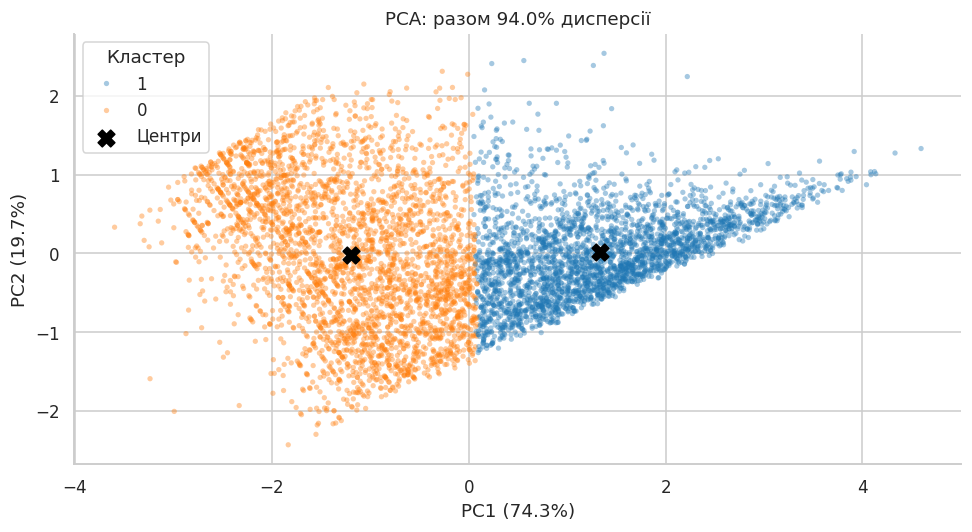

,PC1_coefficient,PC2_coefficient
recency,-0.5044,0.8520
active_days,0.6230,0.2468
monetary,0.5979,0.4616


In [24]:
pca = PCA(n_components=2)
projection = pca.fit_transform(final_values)
plot_idx = np.random.default_rng(42).choice(len(recent),size=min(6000,len(recent)),replace=False)
center_projection = pca.transform(final_model.cluster_centers_)
fig, ax = plt.subplots(figsize=(9,5))
sns.scatterplot(x=projection[plot_idx,0],y=projection[plot_idx,1],
    hue=final_labels[plot_idx].astype(str),palette='tab10',s=12,alpha=.4,linewidth=0,ax=ax)
ax.scatter(center_projection[:,0],center_projection[:,1],c='black',marker='X',s=120,label='Центри')
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',
       ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})',
       title=f'PCA: разом {pca.explained_variance_ratio_.sum():.1%} дисперсії')
ax.legend(title='Кластер'); plt.tight_layout(); plt.show()
save(pd.DataFrame(pca.components_.T,index=features,columns=['PC1_coefficient','PC2_coefficient']),
     'pca_coefficients')


## 6. Висновки

1. Після агрегації отримано 29 786 покупців. Логарифмування зменшило вплив довгих хвостів;
   експеримент з крайніми середніми цінами не дав підстав автоматично їх обрізати.
2. Канал істотно впливав на початкове розбиття. Для сегментації за активністю та витратами
   його залишено для опису, а не для розрахунку відстаней.
3. Річна модель виділила два стійкі профілі. Активніша група становить 47.2% покупців за рік
   і формує 85.0% річної суми покупок. Ще 8 003 клієнти не купували за цей рік і враховані окремо.
4. Часова гіпотеза отримала підтримку: 13.3% великих історичних покупців не купували понад 180 днів.
   На однаковій когорті зміна горизонту агрегації змінила належність до профілів для 11.5% клієнтів.
   Тому історичну цінність і недавню активність варто аналізувати окремо.

**Практичне застосування.** Для активнішого профілю можна перевірити персональні рекомендації
та утримання. Для клієнтів із великими минулими витратами й давньою покупкою — окрему реактиваційну
пропозицію. Це гіпотези для експериментів, а не доведений ефект маркетингових дій.

**Обмеження.** Робота описує історичну вибірку й один зріз. Відсутність покупок не встановлює
причини відходу. Сума price не є прибутком, а внутрішні метрики не перевіряють майбутню цінність
клієнта. Висновки про перевагу кампаній потребують окремої перевірки.


In [25]:
final_customers.to_parquet(OUTPUT_DIR/'annual_customer_segments.parquet')
inactive.to_parquet(OUTPUT_DIR/'customers_without_purchases_365.parquet')
no_purchase.to_csv(OUTPUT_DIR/'sampled_customers_without_history.csv',index=False)
manifest = {'versions':versions,'seed':SEED,'reference_date':str(reference.date()),
            'window_start':str(start.date()),'sampled_customers':len(sampled_customers),
            'buyers_full_history':len(df),'buyers_365':len(recent),
            'final_features':features,'selected_k':chosen,
            'pca_explained_variance_ratio':pca.explained_variance_ratio_.tolist()}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
print('Таблиці:',shutil.make_archive(str(OUTPUT_DIR/'final_tables'),'zip',OUT))


Таблиці: /content/drive/MyDrive/DataMining/segmentation_final/final_tables.zip


### Джерела

- [H&M Personalized Fashion Recommendations — дані](https://www.kaggle.com/competitions/h-and-m-personalized-fashion-recommendations/data).
- [scikit-learn: K-means та оцінювання кластеризації](https://scikit-learn.org/stable/modules/clustering.html).
- [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [Davies–Bouldin](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html).
- [Calinski–Harabasz](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.calinski_harabasz_score.html).
- [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).
